## Pegasus Evaluation: Depth

Section B.3. Setup, methods and metrics: `2a_base_case.ipynb`; parameters: `pegasus/evaluation_setup.py`.
B.3 runs on `tree_source`.

In [1]:
# Data source of B.3:
# - "real": the fork-join trees measured on the second testbed machine (statics/results_milos_v2/b3-vm/, VM_TREE_SETS in pegasus/real_data.py)
# - "synthetic": balanced trees of the three generated services of B.1, with a simulated ground truth (pegasus/trees.py)
tree_source = "real"

# the parameters and helpers that every evaluation notebook shares, defined once in pegasus/evaluation_setup.py
from pegasus.evaluation_setup import *
import pandas as pd
from pegasus.figures import math_label, sweep_table, time_table
p_label = math_label(p_label)   # the quantile name in the math notation of the paper, e.g. $P_{95}$, for the figures and the text
# synthetic trees reuse the configurations and the training data of the synthetic base case of B.1, read from
# statics/evaluation_cache/ or computed here (b1_base); the measured trees need no base case
if tree_source == "synthetic":
    globals().update(b1_base("synthetic"))
print(f"{tree_source} trees, {len(seeds)} seeds")

real trees, 3 seeds


### B.3 Varying Depth of a Map-Reduce Application

Fork-join trees: the leaves alternate between two detectors, every inner service is an aggregator; every frame goes to
all leaves, and the root releases it once both children of every aggregator have. A *balanced* tree with $h$ levels
(`tree_levels`) has $2^h - 1$ services, because every aggregator has two children, so level $i$ holds $2^{i-1}$ services.
Every method bounds each leaf-to-root path and takes the maximum over the paths (`compare_tree_methods`).

- **Real (`tree_source = "real"`):** the balanced trees measured on the second testbed machine, a virtual machine
  with 75 cores (`statics/results_milos_v2/b3-vm/`; object and face detector as leaves, image transformer as
  aggregator, one worker and 1.5 cores each, 8 configurations repeated 6 times per tree). Two tree sets
  (`VM_TREE_SETS` in `pegasus/real_data.py`), each with its own figure:
  - *Large trees* (the main set): image resolutions 288 to 640 px, $h$ = 1 to 6, 8 configurations drawn anew for every
    $h$. A tree that the campaign is still measuring is a preliminary point, marked † (`tree_preliminary`), evaluated
    on the runs it has so far.
  - *Small trees*: 160 to 256 px, $h$ = 1 to 4, the same 8 configurations at every $h$. Left out: $h$ = 5 and 6, whose
    camera could not send the frames to all leaves at their arrival rate (`VM_TREE_SETS`).

  Training: every service type on the grid benchmark of the same machine (`VM_TREE_BENCHMARKS`), the face detector and
  the image transformer on the 1.5-core grid (`grid15-*`), the object detector on the 8-core grid (`grid-*`), the only
  grid that contains it. Handling overhead of a service that receives its frames from another service: measured on the
  other trees of the set (`tree_handling_overhead`). Held-out runs: throttled for less than `TREE_THROTTLE_LIMIT` of
  their CPU periods at every node.
  In the tightness figure of the large trees, the dotted vertical line marks the height at which the median slowdown
  of their services (defined in the slowdown section below) first exceeds `SLOWDOWN_ONSET`, interpolated linearly
  between heights. The dashed line is Pegasus Node against a simulated ground truth from $h$ = `SIMULATED_FROM` on:
  the same held-out runs (configurations and arrival rates) and the same bounds as the solid line, with every service executing as in its benchmark (`emulated_tree_quantiles`: FIFO fork-join queues, execution
  times replayed from benchmark runs that did not train the models of the seed, without the time between the services).
- **Synthetic (`tree_source = "synthetic"`):** balanced trees of the three services of B.1, Poisson arrivals at
  `tree_utilization` of the slowest service.
- **Methods:** as in B.1 without DNN Sum; Pegasus SNC only on the synthetic trees.

Figures: `figures/tsc/b3_trees_real_<tree set>` (real) and `figures/tsc/b3_trees_synthetic` (tightness, training and
evaluation time).

In [2]:
# the options of the data source of B.3
tree_setup = configure(tree_source)
if "B.3" in tree_setup["skipped"]:
    print("B.3 skipped: not supported by the {} data".format(tree_source))
else:
    tree_levels = tree_setup["tree_levels"]
    tree_seeds = tree_setup["tree_seeds"]   # the seeds of every experiment
    # (tree set, levels h) -> valid runs so far of a tree that the campaign is still measuring (real data only)
    tree_preliminary = tree_setup.get("tree_preliminary") or {}
    # B.3: balanced fork-join trees, (shape, levels) -> (children, the service type or node of every position); the shape
    # "balanced" stays in the key, because the results are keyed by shape (sweep_statistics below)
    if tree_source == "synthetic":   # pegasus/trees.py
        trees = {("balanced", h): balanced_tree(h) for h in tree_levels}
        tree_experiments = None
    else:                            # the topology of every measured balanced tree (tree_structure in pegasus/real_data.py)
        tree_experiments = tree_setup["tree_experiments"]
        trees = {key: tree_structure(experiment)[:2] for key, experiment in tree_experiments.items()}
    # the synthetic trees reuse the configurations and the training data of the synthetic base case of B.1 (setup cell)
    tree_bases = bases if tree_source == "synthetic" else None

    def compute():
        def tree_data(shape, levels, s):
            children, path = trees[(shape, levels)]
            if tree_source == "real":   # the measured runs of the tree, every service trained on its benchmark
                return real_tree_data(tree_experiments[(shape, levels)], level=1 - alpha, node_level=1 - alpha / len(path),
                                      coverage_check=coverage_check, seed=[seed, s], **tree_setup["base_options"])
            data = synthetic_tree_data(children, path, level=1 - alpha, node_level=1 - alpha / len(path), coverage_check=coverage_check,
                                       seed=[seed, s], utilization=tree_setup["tree_utilization"], service_seed=s)
            # the configurations and training data of B.1, every configuration with one worker
            assert same_configurations(model_inputs(data.x_test, data.workers_column), model_inputs(tree_bases[s].x_test, tree_bases[s].workers_column)), \
                "the held-out configurations differ from those of B.1"
            assert all(np.array_equal(data.y_train[name], tree_bases[s].y_train[name]) for name in data.y_train), "the training data differs from that of B.1"
            assert_unseen(data)
            return data

        tree_truth, tree_methods, tree_seconds = {}, {}, {}   # shape -> (levels, seed) -> ...
        with warnings.catch_warnings():
            # for some services the fitted GP hyperparameters end at their bounds, and scikit-learn warns for every such model
            warnings.simplefilter("ignore", ConvergenceWarning)
            for s in tree_seeds:
                for shape, levels in trees:
                    data = tree_data(shape, levels, s)
                    models = fit_services(data, data.x_train, data.y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)
                    tree_methods.setdefault(shape, {})[(levels, s)], tree_seconds.setdefault(shape, {})[(levels, s)] = compare_tree_methods(
                        data, models, alpha, confidence, n_calibration, model_seed=seed + s, leave_out=only_base_case)
                    tree_truth.setdefault(shape, {})[(levels, s)] = (data.measured, data.measured_low)
                print(f"seed {s}: {len(trees)} trees evaluated")
        return dict(tree_truth=tree_truth, tree_methods=tree_methods, tree_seconds=tree_seconds)

    globals().update(cached("b3_trees", tree_source, compute, inputs=dict(
        tree_levels=tree_levels, tree_seeds=tree_seeds, tree_options=dict(tree_utilization=tree_setup.get("tree_utilization"), tree_experiments=tree_experiments,
                                                     tree_preliminary=tree_preliminary))))

b3_trees: results loaded from statics/evaluation_cache/b3_trees_real+b1+b1u-max3_99b8e6ed9dcaafd3.joblib


In [3]:
# Additions to the tightness figure of the large trees (real data only): where the services start to slow down, and
# Pegasus Node against a simulated ground truth (emulated_tree_quantiles in pegasus/evaluation.py)
tree_overlay, tree_onset = {}, {}   # shape -> (settings, statistics, label) of the dashed lines; shape -> (h, label) of the vertical line
if tree_source == "real":
    from pegasus.evaluation import emulated_tree_quantiles, slowdown_onset, tree_slowdowns
    from pegasus.real_data import RESULTS_V2, VM_TREE_SETS, VM_V2
    SLOWDOWN_ONSET = 1.03   # the services count as slowed down once their median slowdown exceeds this (3% slower than in the benchmark)
    SIMULATED_FROM = 3      # the first height of the simulated trees
    # the slowdown of every service in every run of both tree sets with h = 1 to 6, also for the slowdown figure below
    slowdown_experiments = {(tree_set, h): f"{VM_V2.name}/{prefix}{h}" for tree_set, (prefix, _) in VM_TREE_SETS.items()
                            for h in range(1, 7) if (RESULTS_V2 / VM_V2.name / f"{prefix}{h}").is_dir()}
    slowdowns = tree_slowdowns(slowdown_experiments)   # one row per run and service
    onset = slowdown_onset(slowdowns, "large", SLOWDOWN_ONSET)
    if onset is not None:
        tree_onset["large"] = (onset, f"slowdown > {SLOWDOWN_ONSET:g}×")
    # the held-out runs of every large tree from SIMULATED_FROM on, with every service as fast as in its benchmark; the bounds
    # are those of the measured trees (tree_methods), only the ground truth differs
    simulated_levels = [h for shape, h in trees if shape == "large" and h >= SIMULATED_FROM]
    simulated_truth = {(h, s): quantiles for h in simulated_levels
                       for s, quantiles in emulated_tree_quantiles(tree_experiments[("large", h)], [[seed, s] for s in tree_seeds],
                                                                   tree_setup["base_options"]["n_train"], 1 - alpha, coverage_check).items()}
    simulated_methods = {key: {PROPOSED: value[PROPOSED]} for key, value in tree_methods["large"].items()
                         if key[0] in simulated_levels}
    tree_overlay["large"] = (simulated_levels, sweep_statistics(simulated_methods, simulated_truth, simulated_levels, tree_seeds, confidence),
                             "simulated")

B.3 balanced fork-join trees, real data, large trees (288 to 640 px): leaves object and face detector, aggregators image transformer, one worker each, 4 to 48 held-out runs per tree,
Poisson arrivals at 50% utilization of the slowest service, 3 seeds (training draws)
legend_inside: the legend hides 5 points or bands at its best location (upper center)


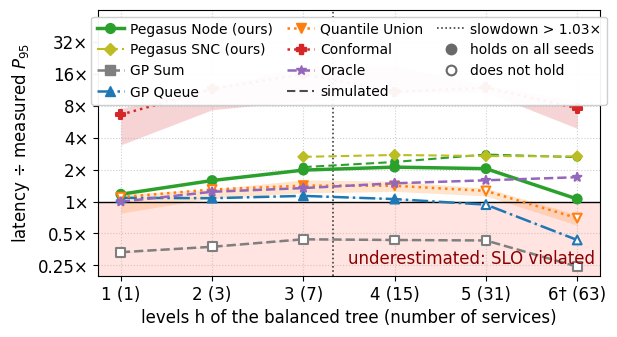

legend_inside: the legend hides 1 points or bands at its best location (upper center)
legend_inside: the legend hides 11 points or bands at its best location (upper center)


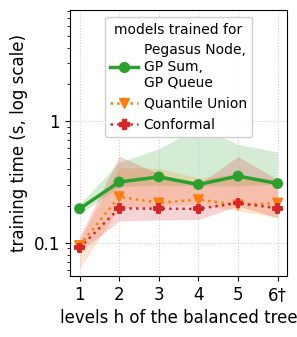

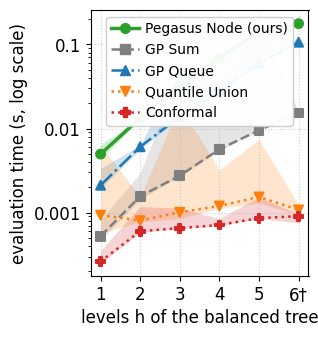

† preliminary: h = 6 from the 4 valid runs measured so far; the campaign is still measuring this tree
B.3 balanced fork-join trees, real data, small trees (160 to 256 px): leaves object and face detector, aggregators image transformer, one worker each, 36 to 48 held-out runs per tree,
Poisson arrivals at 50% utilization of the slowest service, 3 seeds (training draws)
legend_inside: the legend hides 4 points or bands at its best location (upper center)


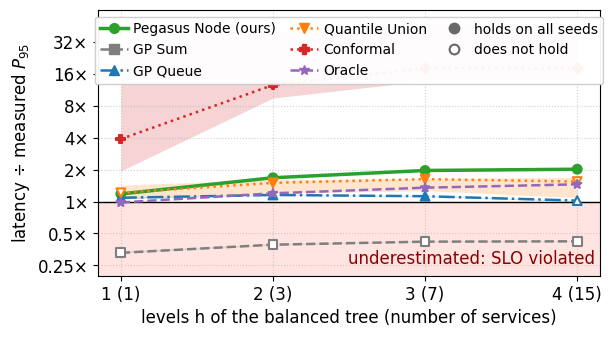

legend_inside: the legend hides 5 points or bands at its best location (upper center)


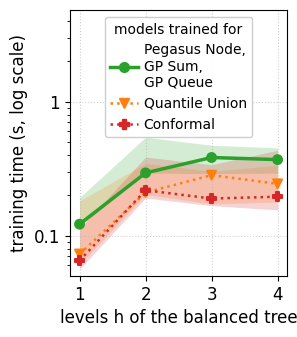

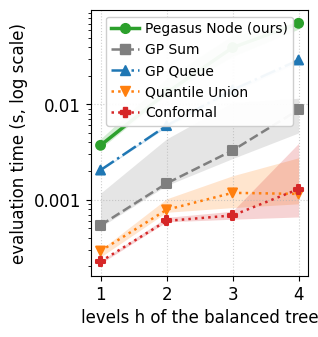

In [4]:
if "B.3" in tree_setup["skipped"]:
    print("B.3 skipped: not supported by the {} data".format(tree_source))
else:
    # the shapes (synthetic) or tree sets (real, VM_TREE_SETS in pegasus/real_data.py) in the order of `trees`, each with its levels h
    tree_shapes = {shape: [h for of, h in trees if of == shape] for shape, _ in trees}
    # the resolution range of a real tree set, from the experiment.yaml of its trees
    shape_text = {"balanced": "balanced", "large": "large trees (288 to 640 px)", "small": "small trees (160 to 256 px)"}
    mark = lambda shape, h: "†" if (shape, h) in tree_preliminary else ""   # a preliminary point (setup cell)
    tree_statistics, tree_times = {}, {}   # shape -> name -> coverage, tightness, holds, computed; shape -> name -> training, evaluation
    for shape, levels in tree_shapes.items():
        tree_statistics[shape] = sweep_statistics(tree_methods[shape], tree_truth[shape], levels, tree_seeds, confidence)
        tree_times[shape] = sweep_seconds(tree_seconds[shape], levels, tree_seeds)
        if tree_source == "real":   # Pegasus SNC only on the synthetic trees
            tree_statistics[shape].pop(PROPOSED_SNC, None)
            tree_times[shape].pop(PROPOSED_SNC, None)
        size_ticks = [f"{h}{mark(shape, h)} ({len(trees[(shape, h)][1])})" for h in levels]   # one row: the fixed layout of every figure
        if tree_source == "synthetic":
            title = (f"B.3 balanced fork-join trees, synthetic data: leaves s1, s2, aggregators s3, one worker each, "
                     f"{len(base.measured)} held-out configurations per seed,\n{workload['process']} arrivals at "
                     f"{tree_setup['tree_utilization']:.0%} utilization of the slowest service, {len(tree_seeds)} seeds")
        else:
            from pegasus.real_data import run_table
            # the utilization of the slowest service at which the campaign set the arrival rate of every run
            tree_utilization = sorted({float(u) for (of, _), experiment in tree_experiments.items() if of == shape
                                       for u in run_table(experiment)["utilization_asked"]})
            held_out = sorted({len(measured) for measured, _ in tree_truth[shape].values()})   # held-out runs of every tree
            runs_text = f"{held_out[0]}" if len(held_out) == 1 else f"{held_out[0]} to {held_out[-1]}"
            title = (f"B.3 balanced fork-join trees, real data, {shape_text[shape]}: leaves object and face detector, aggregators image "
                     f"transformer, one worker each, {runs_text} held-out runs per tree,\nPoisson arrivals at "
                     f"{' and '.join(f'{u:.0%}' for u in tree_utilization)} utilization of the slowest service, {len(tree_seeds)} seeds (training draws)")
        tightness_and_time_figure(levels, tree_statistics[shape], tree_times[shape], "levels h of the balanced tree (number of services)",
                                  title, p_label, tick_labels=size_ticks, log_x=False,
                                  name=f"b3_trees_{tree_source}" if shape == "balanced" else f"b3_trees_{tree_source}_{shape}",
                                  # the two time figures side by side in the width of one: too narrow for "h (N)" at every tick, and the
                                  # tightness figure already gives N for every h
                                  time_halves=("levels h of the balanced tree", [f"{h}{mark(shape, h)}" for h in levels]),
                                  overlay=tree_overlay.get(shape), onset=tree_onset.get(shape))
        for (of, h), runs in tree_preliminary.items():
            if of == shape:
                print(f"† preliminary: h = {h} from the {runs} valid runs measured so far; the campaign is still measuring this tree")

In [5]:
if "B.3" in tree_setup["skipped"]:
    print("B.3 skipped: not supported by the {} data".format(tree_source))
else:
    for shape, levels in tree_shapes.items():
        tree_label = lambda h: f"h = {h}{mark(shape, h)} ({len(trees[(shape, h)][1])})"   # levels (number of services)
        print(f"{shape_text[shape].capitalize()} ({tree_source} data; tightness, median over the seeds; ● holds, ○ does not):")
        shown = [name for name in sweep_competitors + ["Oracle"] if name in tree_statistics[shape]]
        display(sweep_table(levels, tree_statistics[shape], shown, tree_label, tree_truth[shape], tree_seeds))
        print("Training and evaluation time (s, median over the seeds):")
        display(time_table(levels, tree_times[shape], [name for name in sweep_competitors if name in tree_times[shape]], tree_label))

Large trees (288 to 640 px) (real data; tightness, median over the seeds; ● holds, ○ does not):


,h = 1 (1),h = 2 (3),h = 3 (7),h = 4 (15),h = 5 (31),h = 6† (63)
Pegasus Node (ours),1.17× ●,1.58× ●,1.98× ●,2.11× ●,2.04× ●,1.06× ●
GP Sum,0.33× ○,0.37× ○,0.44× ○,0.43× ○,0.43× ○,0.24× ○
GP Queue,1.08× ●,1.07× ●,1.13× ●,1.05× ●,0.93× ○,0.43× ○
Quantile Union,1.10× ○,1.30× ○,1.41× ●,1.41× ●,1.26× ○,0.70× ○
Conformal,6.57× ●,11.48× ●,15.85× ●,10.77× ●,11.80× ●,7.58× ●
Oracle,1.00× ●,1.24× ●,1.34× ●,1.48× ●,1.58× ●,1.69× ●
measured (s),0.525,0.64,0.508,0.449,1.01,2.05


Training and evaluation time (s, median over the seeds):


,h = 1 (1),h = 2 (3),h = 3 (7),h = 4 (15),h = 5 (31),h = 6† (63)
"training: Pegasus Node (ours), GP Sum, GP Queue",0.19,0.32,0.35,0.3,0.35,0.31
training: Quantile Union,0.095,0.24,0.21,0.23,0.2,0.21
training: Conformal,0.091,0.19,0.19,0.19,0.21,0.19
evaluation: Pegasus Node (ours),0.005,0.013,0.032,0.068,0.14,0.18
evaluation: GP Sum,0.00052,0.0016,0.0027,0.0057,0.0095,0.015
evaluation: GP Queue,0.0021,0.0061,0.014,0.027,0.06,0.11
evaluation: Quantile Union,0.00093,0.0008,0.001,0.0012,0.0015,0.0011
evaluation: Conformal,0.00026,0.0006,0.00065,0.00071,0.00086,0.00091


Small trees (160 to 256 px) (real data; tightness, median over the seeds; ● holds, ○ does not):


,h = 1 (1),h = 2 (3),h = 3 (7),h = 4 (15)
Pegasus Node (ours),1.18× ●,1.67× ●,1.96× ●,2.01× ●
GP Sum,0.33× ○,0.39× ○,0.42× ○,0.42× ○
GP Queue,1.08× ●,1.15× ●,1.12× ●,1.02× ○
Quantile Union,1.21× ○,1.50× ●,1.62× ●,1.54× ○
Conformal,3.88× ●,12.49× ●,17.99× ●,17.85× ●
Oracle,0.98× ●,1.19× ●,1.35× ●,1.45× ●
measured (s),0.108,0.123,0.14,0.19


Training and evaluation time (s, median over the seeds):


,h = 1 (1),h = 2 (3),h = 3 (7),h = 4 (15)
"training: Pegasus Node (ours), GP Sum, GP Queue",0.12,0.29,0.38,0.37
training: Quantile Union,0.073,0.21,0.28,0.24
training: Conformal,0.065,0.22,0.19,0.2
evaluation: Pegasus Node (ours),0.0037,0.013,0.039,0.07
evaluation: GP Sum,0.00054,0.0015,0.0033,0.0088
evaluation: GP Queue,0.002,0.006,0.014,0.029
evaluation: Quantile Union,0.00029,0.00079,0.0012,0.0012
evaluation: Conformal,0.00023,0.0006,0.00069,0.0013


#### Slowdown of the services against their concurrency

- *Slowdown* of a service in a run: its mean processing time in the tree divided by that of its grid benchmark at the
  same configuration (`VM_TREE_BENCHMARKS`; the median over the benchmark runs at the utilizations u = 0.4, 0.6 and 0.8
  of the service). A slowdown of 1 means as fast as in the benchmark.
- *Concurrency* $c$ of a service in a run: the time-weighted mean number of the other services of the tree that are
  processing while the service processes an item (`trace_steps.csv`).
- *Data:* every run of both tree sets in `statics/results_milos_v2/b3-vm/` with $h$ = 1 to 6 whose services were
  throttled for less than `TREE_THROTTLE_LIMIT` (`tree_slowdowns` in `pegasus/evaluation.py`), also the small trees with
  $h$ = 5 and 6: their camera delays the frames before they reach the services, not the processing. The large tree with
  $h$ = 6 is preliminary (†).
- *Figure* (`figures/tsc/b3_slowdown_concurrency`): per service type, the median slowdown of the service × run pairs in
  every bin of $c$ (`CONCURRENCY_BINS`), drawn at the median $c$ of the bin, with the band from the 10th to the 90th
  percentile; a bin with fewer than 10 pairs is left out. The black line at 1 is the speed of the benchmark; the dotted
  vertical lines are the median concurrency of the large trees with $h$ = 3 to 6. Table: the same per height of the
  large trees.

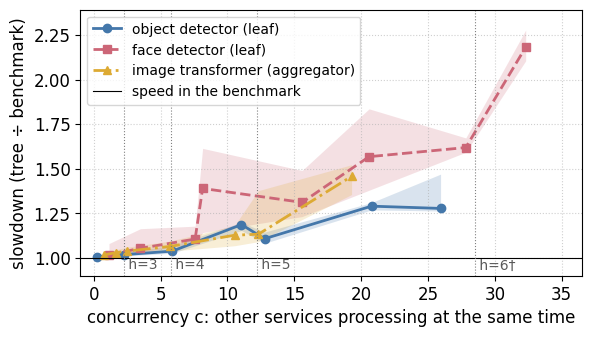

Large trees, per height (median over the services and runs):


,runs,concurrency c,slowdown,"slowdown, 90th percentile"
h,,,,
h = 1,48,0.0,1.00,1.00
h = 2,48,0.7,1.01,1.02
h = 3,48,2.3,1.02,1.06
h = 4,48,5.8,1.05,1.12
h = 5,48,12.2,1.11,1.36
h = 6†,4,28.5,1.46,2.19


In [6]:
# B.3 diagnosis: the slowdown of every service against the concurrency it saw (tree_slowdowns in pegasus/evaluation.py),
# both tree sets with h = 1 to 6 (statics/results_milos_v2/b3-vm/)
if tree_source == "real":
    from pegasus.evaluation import slowdown_figure
    # slowdowns: one row per run and service of both tree sets, from the cell before the tightness figure
    large = slowdowns[slowdowns["tree_set"] == "large"]
    # where the heights of the large trees lie: the median concurrency of their services
    large_concurrency = large.groupby("h")["concurrency"].median()
    slowdown_figure(slowdowns, {f"h={h}{mark('large', h)}": c for h, c in large_concurrency.items() if h >= 3}, name="b3_slowdown_concurrency")

    by_height = large.groupby("h")
    print("Large trees, per height (median over the services and runs):")
    display(pd.DataFrame({"runs": by_height["run_id"].nunique(), "concurrency c": by_height["concurrency"].median().round(1),
                          "slowdown": by_height["slowdown"].median().round(2),
                          "slowdown, 90th percentile": by_height["slowdown"].quantile(0.9).round(2)},
                         ).rename(index=lambda h: f"h = {h}{mark('large', h)}"))